##первая часть

In [ ]:
import pandas as pd, numpy as np, networkx as nx
from urllib.parse import unquote
from collections import Counter
import matplotlib.pyplot as plt

BASE = '/content'  # подставь свой путь в Colab

# Статьи
articles = pd.read_csv(f'{BASE}/articles.tsv', sep='\t', header=None,
                       names=['article'], comment='#', quoting=3)
articles['name'] = articles['article'].apply(unquote)
print('articles:', len(articles))
print(articles['name'].head(10).tolist())

# Связи
links = pd.read_csv(f'{BASE}/links.tsv', sep='\t', header=None,
                    names=['src','tgt'], comment='#', quoting=3)
links['src'] = links['src'].apply(unquote)
links['tgt'] = links['tgt'].apply(unquote)
print('links:', len(links))

# Категории
cats = pd.read_csv(f'{BASE}/categories.tsv', sep='\t', header=None,
                   names=['article','category'], comment='#', quoting=3)
cats['article']  = cats['article'].apply(unquote)
cats['category'] = cats['category'].apply(unquote)
print('categories:', len(cats))

# Пути
fin = pd.read_csv(f'{BASE}/paths_finished.tsv', sep='\t', header=None,
                  names=['ip','timestamp','duration','path','rating'],
                  comment='#', quoting=3)
unf = pd.read_csv(f'{BASE}/paths_unfinished.tsv', sep='\t', header=None,
                  names=['ip','timestamp','duration','path','target','type'],
                  comment='#', quoting=3)
print('finished:', len(fin), 'unfinished:', len(unf))
print(unf.head(2))

articles: 4604
['Áedán_mac_Gabráin', 'Åland', 'Édouard_Manet', 'Éire', 'Óengus_I_of_the_Picts', '€2_commemorative_coins', '10th_century', '11th_century', '12th_century', '13th_century']
links: 119882
categories: 5204
finished: 51318 unfinished: 24875
                 ip   timestamp  duration            path     target     type
0  2426091a53125110  1297054935      1804  Obi-Wan_Kenobi  Microsoft  timeout
1  26141fd878806294  1297055651      1805   Julius_Caesar    Caracas  timeout


In [ ]:
def parse_path(p):
    """Возвращает (raw_path, effective_path).
    raw: как кликал (с повторами от '<')
    effective: без back-кликов (упрощённая цепочка)"""
    tokens = [unquote(t) for t in p.split(';')]
    raw, eff = [], []
    for t in tokens:
        if t == '<':
            if eff: eff.pop()
            if raw: raw.append(raw[-2]) if False else None
            # для raw просто игнорируем '<' (петля назад)
        else:
            raw.append(t)
            eff.append(t)
    return raw, eff

# sanity check
print(parse_path('Emirate;Kuwait;<;Qatar'))

(['Emirate', 'Kuwait', 'Qatar'], ['Emirate', 'Qatar'])


count    51318.000000
mean         5.356775
std          3.775778
min          0.000000
25%          3.000000
50%          5.000000
75%          6.000000
max        419.000000
Name: n_hops_raw, dtype: float64
rating distribution:
 rating
NaN    22817
2.0     8792
1.0     8542
3.0     7261
4.0     2748
5.0     1158
Name: count, dtype: int64
unfinished types:
 type
restart    15552
timeout     9323
Name: count, dtype: int64


Text(0.5, 1.0, 'Unfinished hops (raw)')

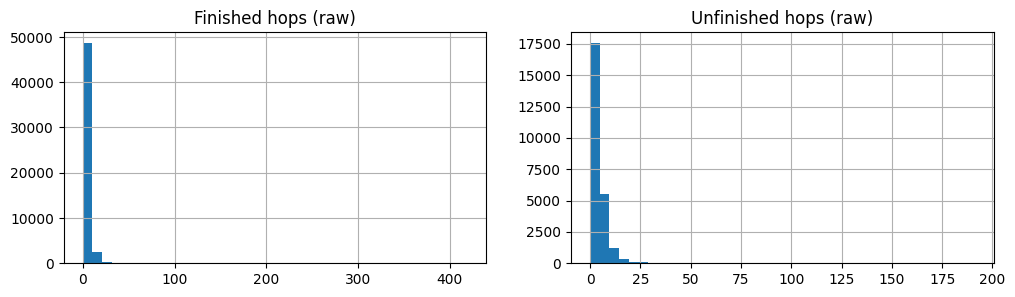

In [ ]:
fin['raw'],   fin['eff'] = zip(*fin['path'].map(parse_path))
unf['raw'],   unf['eff'] = zip(*unf['path'].map(parse_path))

fin['n_hops_raw'] = fin['raw'].map(lambda s: len(s)-1)
fin['n_hops_eff'] = fin['eff'].map(lambda s: len(s)-1)
print(fin['n_hops_raw'].describe())
print('rating distribution:\n', fin['rating'].value_counts(dropna=False))

unf['n_hops_raw'] = unf['raw'].map(lambda s: len(s)-1)
print('unfinished types:\n', unf['type'].value_counts())

fig, ax = plt.subplots(1,2, figsize=(12,3))
fin['n_hops_raw'].hist(bins=40, ax=ax[0]); ax[0].set_title('Finished hops (raw)')
unf['n_hops_raw'].hist(bins=40, ax=ax[1]); ax[1].set_title('Unfinished hops (raw)')

In [ ]:
inter = Counter()
for seq in fin['raw']:
    inter.update(seq[1:-1])   # не считаем старт/финиш
print('TOP intermediate articles:')
for name, c in inter.most_common(20): print(f'{c:5d}  {name}')

drop = Counter()
for seq in unf['raw']:
    if seq: drop[seq[-1]] += 1
print('\nTOP drop-off articles:')
for name, c in drop.most_common(20): print(f'{c:5d}  {name}')

# нормализация по входящему трафику — «бросают непропорционально часто»
visits = Counter()
for seq in list(fin['raw']) + list(unf['raw']):
    visits.update(seq)
ratio = {a: drop[a]/visits[a] for a in drop if visits[a] >= 50}
top_ratio = sorted(ratio.items(), key=lambda x: -x[1])[:20]
print('\nTOP drop-off rate (>=50 visits):')
for a, r in top_ratio: print(f'{r:5.2%}  {a}  (visits={visits[a]})')

TOP intermediate articles:
 8824  United_States
 4319  Europe
 3860  United_Kingdom
 3153  Earth
 3123  England
 2693  Africa
 2225  World_War_II
 1804  North_America
 1676  Germany
 1659  Animal
 1584  Mammal
 1580  Human
 1573  France
 1438  Science
 1359  English_language
 1351  Periodic_table
 1325  Computer
 1281  Atlantic_Ocean
 1188  India
 1147  Agriculture

TOP drop-off articles:
  621  United_States
  279  England
  279  United_Kingdom
  231  Brain
  187  Europe
  183  Theatre
  160  India
  159  France
  157  Mammal
  149  Africa
  149  Earth
  145  Animal
  125  World_War_II
  124  Human
  123  Asteroid
  121  North_America
  109  Protein
  106  Pyramid
  104  Batman
  103  English_language

TOP drop-off rate (>=50 visits):
54.92%  Wikipedia_Text_of_the_GNU_Free_Documentation_License  (visits=122)
29.51%  Canadian_Senate  (visits=61)
24.36%  Salsa_music  (visits=156)
22.31%  Muhammad  (visits=130)
20.80%  London_Underground  (visits=125)
19.03%  Coffee  (visits=226)
18.92% 

In [ ]:
G = nx.from_pandas_edgelist(links, 'src', 'tgt',
                            create_using=nx.DiGraph())
print('nodes:', G.number_of_nodes(), 'edges:', G.number_of_edges())

# Загрузка Floyd-Warshall матрицы (порядок строк = порядок articles.tsv)
with open(f'{BASE}/shortest-path-distance-matrix.txt') as f:
    lines = [l.strip() for l in f if l.strip() and not l.startswith('#')]
n = len(articles)
D = np.full((n, n), -1, dtype=int)
for i, line in enumerate(lines):
    for j, ch in enumerate(line):
        D[i, j] = -1 if ch == '_' else int(ch)
idx = {name: i for i, name in enumerate(articles['name'])}
print('matrix shape:', D.shape, 'unreachable %:', (D==-1).mean())

# сверка с BFS на паре случайных пар
import random
for _ in range(5):
    a, b = random.sample(list(G.nodes), 2)
    d_bfs = nx.shortest_path_length(G, a, b) if nx.has_path(G, a, b) else -1
    d_mat = D[idx[a], idx[b]] if a in idx and b in idx else None
    print(a, '->', b, 'BFS=', d_bfs, 'Matrix=', d_mat)

nodes: 4592 edges: 119882
matrix shape: (4604, 4604) unreachable %: 0.12284755408548152
Postage_stamp -> Tropical_Storm_Matthew_(2004) BFS= 4 Matrix= 4
Liverpool -> Waheguru BFS= 3 Matrix= 3
Yagan -> Chew_Valley BFS= 5 Matrix= 5
Magna_Carta -> Draughts BFS= -1 Matrix= -1
Wikispecies -> Camel BFS= 4 Matrix= 4


In [ ]:
rows = []
for seq in fin['raw']:
    start, target = seq[0], seq[-1]
    if start not in idx or target not in idx: continue
    sp = D[idx[start], idx[target]]
    if sp <= 0: continue
    actual = len(seq) - 1
    rows.append({'start': start, 'target': target,
                 'shortest': sp, 'actual': actual,
                 'ratio': actual / sp})
cmp_df = pd.DataFrame(rows)
print(cmp_df[['shortest','actual','ratio']].describe())
print('median overhead:', cmp_df['ratio'].median())

# самые «обманчивые» цели (большой overhead при коротком shortest)
cmp_df.groupby('target')['ratio'].agg(['mean','count']).query('count>=20')\
      .sort_values('mean', ascending=False).head(15)

           shortest        actual         ratio
count  51306.000000  51306.000000  51306.000000
mean       2.846100      5.358009      1.895918
std        0.699601      3.775356      1.461998
min        1.000000      1.000000      1.000000
25%        2.000000      3.000000      1.333333
50%        3.000000      5.000000      1.666667
75%        3.000000      6.000000      2.000000
max        6.000000    419.000000    209.500000
median overhead: 1.6666666666666667


,mean,count
target,,
English_language,5.460606,55
IPod,3.427083,32
Mango,3.404762,42
ITunes,3.095833,24
Police_state,2.991667,20
Philosophy,2.984375,32
Jet_engine,2.909722,24
Fire,2.901515,22
Frog,2.893678,29


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

K = 5  # смотрим на первые 5 шагов

def featurize(seq, target, k):
    # Если цель уже достигнута в первых k шагах, не берем этот пример (утечка)
    if target in seq[:k+1]:
        return None
    if len(seq) < 2:
        return None

    prefix = seq[:k+1]
    last = prefix[-1]

    # Дистанции до цели для каждой статьи в префиксе
    dists = [D[idx[a], idx[target]] if (a in idx and target in idx and D[idx[a], idx[target]] != -1) else 99 for a in prefix]

    return {
        'k':             len(prefix) - 1,
        'dist_last':     dists[-1],
        'dist_min':      min(dists),
        'dist_first':    dists[0],
        'dist_delta':    dists[0] - dists[-1],   # >0 — приближаемся
        'in_degree_last': G.in_degree(last) if last in G else 0,
        'back_clicks':   sum(1 for i in range(1, len(prefix)) if prefix[i] == prefix[i-1]), # грубая оценка
    }

feats, labels, groups = [], [], []

# Успешные пути
for seq in fin['raw']:
    f = featurize(seq, seq[-1], K)
    if f:
        feats.append(f)
        labels.append(1)
        groups.append((seq[0], seq[-1])) # кортеж (start, target)

# Провальные пути
for seq, tgt in zip(unf['raw'], unf['target']):
    f = featurize(seq, tgt, K)
    if f:
        feats.append(f)
        labels.append(0)
        groups.append((seq[0], tgt))

X = pd.DataFrame(feats).fillna(0)
y = np.array(labels)

# ИСПРАВЛЕНИЕ ОШИБКИ: делаем 1D массив строк для GroupShuffleSplit
groups = np.array([f"{s}||{t}" for s, t in groups])

print('Dataset shape:', X.shape, 'Pos rate:', y.mean())

# Групповое разделение (чтобы пары start-target не пересекались)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(X, y, groups=groups))

# Проверка, что пары не пересекаются
assert not (set(groups[tr]) & set(groups[te])), "Утечка данных!"
print("Train/Test split успешно создан без пересечений пар start-target.")

# Обучение
sc = StandardScaler().fit(X.iloc[tr])
clf = LogisticRegression(max_iter=1000, class_weight='balanced').fit(sc.transform(X.iloc[tr]), y[tr])
p = clf.predict_proba(sc.transform(X.iloc[te]))[:, 1]

print('ROC-AUC:', roc_auc_score(y[te], p))

# Важность признаков
print("\nВажность признаков:")
for col, w in sorted(zip(X.columns, clf.coef_[0]), key=lambda x: -abs(x[1])):
    print(f'{w:+.3f}  {col}')

Dataset shape: (37680, 7) Pos rate: 0.47823779193205945
Train/Test split успешно создан без пересечений пар start-target.
ROC-AUC: 0.9206633816954102

Важность признаков:
+8.192  k
-6.515  dist_min
-6.231  dist_last
-6.008  dist_first
+1.842  dist_delta
-0.050  in_degree_last
+0.048  back_clicks


In [ ]:
import os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import random

# Загрузка текстов
def load_text(name):
    # Имена в графе могут быть с пробелами, а файлы с подчеркиваниями
    fn = name.replace(' ', '_') + '.txt'
    p = os.path.join(BASE, fn)
    if os.path.exists(p):
        with open(p, encoding='utf-8', errors='ignore') as f:
            return f.read()
    return ""

# Берем только те статьи, которые есть в графе, чтобы не тратить память
names = list(G.nodes)
texts = [load_text(n) for n in names]

print("Векторизация текстов (займет пару секунд)...")
vec = TfidfVectorizer(stop_words='english', max_features=30000) # 30k фич достаточно
mat = vec.fit_transform(texts)
name2i = {n: i for i, n in enumerate(names)}

def agent_path(start, target, max_steps=50):
    path = [start]
    cur = start
    visited = set([start])

    for _ in range(max_steps):
        if cur == target:
            return path, True

        # Все доступные ссылки (соседи)
        nbrs = [v for v in G.successors(cur) if v in name2i]
        # Убираем те, где мы уже были
        nbrs = [v for v in nbrs if v not in visited]

        if not nbrs:
            return path, False # Тупик

        # Считаем косинусное сходство текста цели и текстов соседей
        target_vec = mat[name2i[target]]
        nbr_vecs = mat[[name2i[v] for v in nbrs]]

        sims = cosine_similarity(target_vec, nbr_vecs).ravel()

        # Выбираем соседа с максимальным сходством
        best_idx = int(sims.argmax())
        nxt = nbrs[best_idx]

        path.append(nxt)
        visited.add(nxt)
        cur = nxt

    return path, cur == target

# ТЕСТ АГЕНТА
# Берем 100 случайных успешных пар из людей
sample = cmp_df.sample(100, random_state=42)
agent_success = 0
overheads = []

print("\nЗапуск агента на 100 тестовых парах...")
for idx_row, row in sample.iterrows():
    start, target = row['start'], row['target']
    shortest = row['shortest']

    path, ok = agent_path(start, target)
    if ok:
        agent_success += 1
        overheads.append((len(path) - 1) / shortest)

print(f"Агент успешно дошел в {agent_success}/100 случаях ({agent_success}%).")
if overheads:
    print(f"Средний оверхед агента: {np.mean(overheads):.2f}x (люди в среднем: {sample['ratio'].mean():.2f}x)")

Векторизация текстов (займет пару секунд)...

Запуск агента на 100 тестовых парах...
Агент успешно дошел в 67/100 случаях (67%).
Средний оверхед агента: 1.89x (люди в среднем: 1.82x)


##вторая часть

In [ ]:
import pandas as pd, numpy as np, networkx as nx
from urllib.parse import unquote
from collections import Counter
import matplotlib.pyplot as plt

BASE = '/content'  # подставь свой путь в Colab

# Статьи
articles = pd.read_csv(f'{BASE}/articles.tsv', sep='\t', header=None,
                       names=['article'], comment='#', quoting=3)
articles['name'] = articles['article'].apply(unquote)
print('articles:', len(articles))
print(articles['name'].head(10).tolist())

# Связи
links = pd.read_csv(f'{BASE}/links.tsv', sep='\t', header=None,
                    names=['src','tgt'], comment='#', quoting=3)
links['src'] = links['src'].apply(unquote)
links['tgt'] = links['tgt'].apply(unquote)
print('links:', len(links))

# Категории
cats = pd.read_csv(f'{BASE}/categories.tsv', sep='\t', header=None,
                   names=['article','category'], comment='#', quoting=3)
cats['article']  = cats['article'].apply(unquote)
cats['category'] = cats['category'].apply(unquote)
print('categories:', len(cats))

# Пути
fin = pd.read_csv(f'{BASE}/paths_finished.tsv', sep='\t', header=None,
                  names=['ip','timestamp','duration','path','rating'],
                  comment='#', quoting=3)
unf = pd.read_csv(f'{BASE}/paths_unfinished.tsv', sep='\t', header=None,
                  names=['ip','timestamp','duration','path','target','type'],
                  comment='#', quoting=3)
print('finished:', len(fin), 'unfinished:', len(unf))
print(unf.head(2))

articles: 4604
['Áedán_mac_Gabráin', 'Åland', 'Édouard_Manet', 'Éire', 'Óengus_I_of_the_Picts', '€2_commemorative_coins', '10th_century', '11th_century', '12th_century', '13th_century']
links: 119882
categories: 5204
finished: 51318 unfinished: 24875
                 ip   timestamp  duration            path     target     type
0  2426091a53125110  1297054935      1804  Obi-Wan_Kenobi  Microsoft  timeout
1  26141fd878806294  1297055651      1805   Julius_Caesar    Caracas  timeout


In [ ]:
def parse_path(p):
    """Возвращает (raw_path, effective_path).
    raw: как кликал (с повторами от '<')
    effective: без back-кликов (упрощённая цепочка)"""
    tokens = [unquote(t) for t in p.split(';')]
    raw, eff = [], []
    for t in tokens:
        if t == '<':
            if eff: eff.pop()
            if raw: raw.append(raw[-2]) if False else None
            # для raw просто игнорируем '<' (петля назад)
        else:
            raw.append(t)
            eff.append(t)
    return raw, eff

# sanity check
print(parse_path('Emirate;Kuwait;<;Qatar'))

(['Emirate', 'Kuwait', 'Qatar'], ['Emirate', 'Qatar'])


count    51318.000000
mean         5.356775
std          3.775778
min          0.000000
25%          3.000000
50%          5.000000
75%          6.000000
max        419.000000
Name: n_hops_raw, dtype: float64
rating distribution:
 rating
NaN    22817
2.0     8792
1.0     8542
3.0     7261
4.0     2748
5.0     1158
Name: count, dtype: int64
unfinished types:
 type
restart    15552
timeout     9323
Name: count, dtype: int64


Text(0.5, 1.0, 'Unfinished hops (raw)')

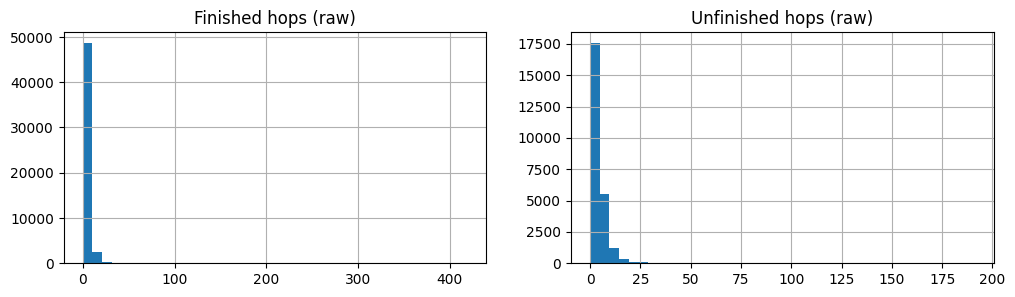

In [ ]:
fin['raw'],   fin['eff'] = zip(*fin['path'].map(parse_path))
unf['raw'],   unf['eff'] = zip(*unf['path'].map(parse_path))

fin['n_hops_raw'] = fin['raw'].map(lambda s: len(s)-1)
fin['n_hops_eff'] = fin['eff'].map(lambda s: len(s)-1)
print(fin['n_hops_raw'].describe())
print('rating distribution:\n', fin['rating'].value_counts(dropna=False))

unf['n_hops_raw'] = unf['raw'].map(lambda s: len(s)-1)
print('unfinished types:\n', unf['type'].value_counts())

fig, ax = plt.subplots(1,2, figsize=(12,3))
fin['n_hops_raw'].hist(bins=40, ax=ax[0]); ax[0].set_title('Finished hops (raw)')
unf['n_hops_raw'].hist(bins=40, ax=ax[1]); ax[1].set_title('Unfinished hops (raw)')

In [ ]:
G = nx.from_pandas_edgelist(links, 'src', 'tgt',
                            create_using=nx.DiGraph())
print('nodes:', G.number_of_nodes(), 'edges:', G.number_of_edges())

# Загрузка Floyd-Warshall матрицы (порядок строк = порядок articles.tsv)
with open(f'{BASE}/shortest-path-distance-matrix.txt') as f:
    lines = [l.strip() for l in f if l.strip() and not l.startswith('#')]
n = len(articles)
D = np.full((n, n), -1, dtype=int)
for i, line in enumerate(lines):
    for j, ch in enumerate(line):
        D[i, j] = -1 if ch == '_' else int(ch)
idx = {name: i for i, name in enumerate(articles['name'])}
print('matrix shape:', D.shape, 'unreachable %:', (D==-1).mean())

# сверка с BFS на паре случайных пар
import random
for _ in range(5):
    a, b = random.sample(list(G.nodes), 2)
    d_bfs = nx.shortest_path_length(G, a, b) if nx.has_path(G, a, b) else -1
    d_mat = D[idx[a], idx[b]] if a in idx and b in idx else None
    print(a, '->', b, 'BFS=', d_bfs, 'Matrix=', d_mat)

nodes: 4592 edges: 119882
matrix shape: (4604, 4604) unreachable %: 0.12284755408548152
Music_of_the_trecento -> Laika BFS= 4 Matrix= 4
Graphic_novel -> Franklin_B._Gowen BFS= -1 Matrix= -1
Caesar_cipher -> ZX_Spectrum BFS= 4 Matrix= 4
The_Bahamas -> Painting BFS= 3 Matrix= 3
Rubik's_Cube -> USS_Wisconsin_(BB-64) BFS= -1 Matrix= -1


In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from collections import Counter

# Предполагаем, что fin (finished), unf (unfinished), G (граф) уже загружены

# --- 1. Фиксированное разбиение по target ---
# Извлекаем цели для всех путей
fin_targets = fin['raw'].apply(lambda x: x[-1])
unf_targets = unf['target']

# Объединяем для создания единого маппинга target -> split
all_targets = pd.concat([fin_targets, unf_targets]).unique()

# Разбиваем сами цели (например, 70% train, 15% val, 15% test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_targets, temp_targets = next(gss.split(all_targets, groups=all_targets))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_targets, test_targets = next(gss2.split(temp_targets, groups=temp_targets))

# Словари для быстрого маппинга
target_to_split = {}
for t in all_targets[train_targets]: target_to_split[t] = 'train'
for t in all_targets[val_targets]:   target_to_split[t] = 'val'
for t in all_targets[test_targets]:  target_to_split[t] = 'test'

print(f"Целей в Train: {len(train_targets)}, Val: {len(val_targets)}, Test: {len(test_targets)}")

# Добавляем колонку split в датафреймы
fin['split'] = fin_targets.map(target_to_split)
unf['split'] = unf_targets.map(target_to_split)

# --- 2. Признаки статей (PageRank, степень) ---
print("Считаем PageRank...")
pagerank = nx.pagerank(G, alpha=0.85)
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

# --- 3. Доля отказов (Drop-off rate) ТОЛЬКО по Train ---
# Считаем, как часто статью бросают, относительно того, как часто в нее заходят
train_visits = Counter()
train_drops = Counter()

for seq in fin[fin['split'] == 'train']['raw']:
    train_visits.update(seq[1:-1]) # промежуточные
for seq in unf[unf['split'] == 'train']['raw']:
    if len(seq) > 1:
        train_visits.update(seq[1:])
        train_drops[seq[-1]] += 1

drop_rate = {}
for article, visits in train_visits.items():
    if visits >= 10: # отсекаем шум
        drop_rate[article] = train_drops[article] / visits
    else:
        drop_rate[article] = 0.0 # Сглаживание

Целей в Train: 2903, Val: 622, Test: 623
Считаем PageRank...


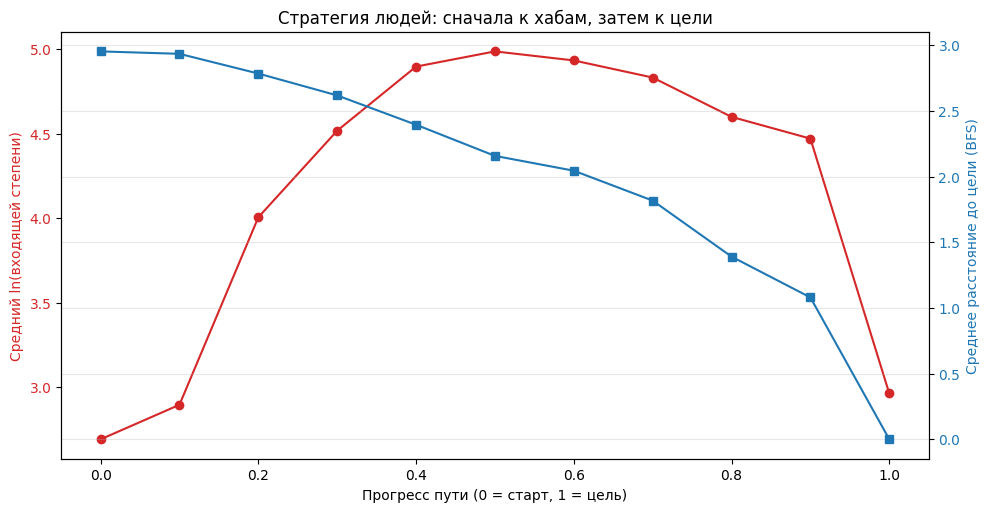

In [ ]:
import matplotlib.pyplot as plt

# Берем только успешные пути из Train, чтобы не загрязнять статистику
train_paths = fin[fin['split'] == 'train']['raw']

# Нормируем шаги от 0 до 1, чтобы усреднить пути разной длины
steps = np.linspace(0, 1, 11)
avg_degree = []
avg_dist_to_target = []

for s in steps:
    degs = []
    dists = []
    for seq in train_paths:
        # Берем индекс, соответствующий прогрессу s (от 0 до len-1)
        idx_step = int(s * (len(seq) - 1))
        article = seq[idx_step]
        target = seq[-1]

        # Степень (логарифмируем для красоты графика)
        degs.append(np.log1p(in_degree.get(article, 0)))

        # Дистанция до цели
        if article in idx and target in idx:
            d = D[idx[article], idx[target]]
            dists.append(d if d != -1 else 99)

    avg_degree.append(np.mean(degs))
    avg_dist_to_target.append(np.mean(dists))

# Визуализация "Сначала к хабу, потом к цели"
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Прогресс пути (0 = старт, 1 = цель)')
ax1.set_ylabel('Средний ln(входящей степени)', color=color)
ax1.plot(steps, avg_degree, color=color, marker='o', label='Степень статьи (Hubness)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Среднее расстояние до цели (BFS)', color=color)
ax2.plot(steps, avg_dist_to_target, color=color, marker='s', label='Расстояние до цели')
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()
plt.title('Стратегия людей: сначала к хабам, затем к цели')
plt.grid(True, alpha=0.3)
plt.show()

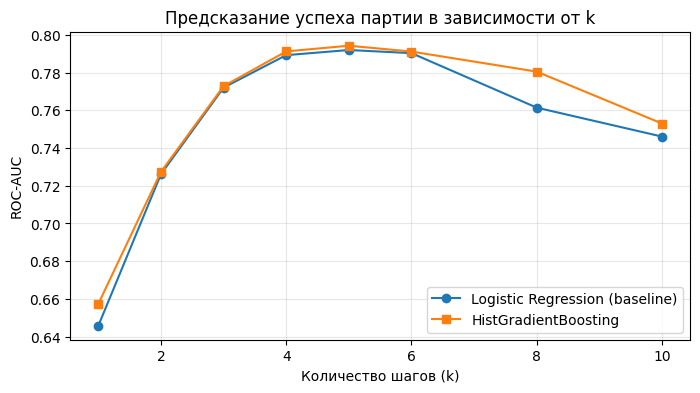

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

def get_features(seq, target, k):
    # Утечка: если цель достигнута за первые k шагов - отбрасываем
    if target in seq[:k+1] or len(seq) < 2:
        return None

    prefix = seq[:k+1]
    last = prefix[-1]

    # Считаем расстояния до цели для каждой статьи в префиксе
    dists = [D[idx[a], idx[target]] if (a in idx and target in idx and D[idx[a], idx[target]] != -1) else 99 for a in prefix]

    return {
        'dist_last': dists[-1],
        'dist_min': min(dists),
        'dist_first': dists[0],
        'dist_delta': dists[0] - dists[-1], # Если > 0, значит человек приближается
        'in_degree_last': in_degree.get(last, 0),
        'pagerank_last': pagerank.get(last, 0),
        'drop_rate_last': drop_rate.get(last, 0),
        'back_clicks': sum(1 for i in range(1, len(prefix)) if prefix[i] == prefix[i-1]),
        'path_len_so_far': k
    }

ks = [1, 2, 3, 4, 5, 6, 8, 10]
results_lr = []
results_gb = []

for k in ks:
    X_tr, y_tr, X_te, y_te = [], [], [], []

    # ИСПРАВЛЕНИЕ: используем zip для итерации по путям и их сплитам
    for seq, split in zip(fin['raw'], fin['split']):
        f = get_features(seq, seq[-1], k)
        if f:
            if split == 'train':
                X_tr.append(f); y_tr.append(1)
            elif split == 'test':
                X_te.append(f); y_te.append(1)

    for seq, tgt, split in zip(unf['raw'], unf['target'], unf['split']):
        f = get_features(seq, tgt, k)
        if f:
            if split == 'train':
                X_tr.append(f); y_tr.append(0)
            elif split == 'test':
                X_te.append(f); y_te.append(0)

    X_tr, y_tr = pd.DataFrame(X_tr), np.array(y_tr)
    X_te, y_te = pd.DataFrame(X_te), np.array(y_te)

    # Логистическая регрессия (бейзлайн)
    sc = StandardScaler().fit(X_tr)
    lr = LogisticRegression(max_iter=1000).fit(sc.transform(X_tr), y_tr)
    results_lr.append(roc_auc_score(y_te, lr.predict_proba(sc.transform(X_te))[:, 1]))

    # Бустинг (КТ2)
    gb = HistGradientBoostingClassifier(max_iter=100, random_state=42).fit(X_tr, y_tr)
    results_gb.append(roc_auc_score(y_te, gb.predict_proba(X_te)[:, 1]))

# График качества от k
plt.figure(figsize=(8, 4))
plt.plot(ks, results_lr, marker='o', label='Logistic Regression (baseline)')
plt.plot(ks, results_gb, marker='s', label='HistGradientBoosting')
plt.xlabel('Количество шагов (k)')
plt.ylabel('ROC-AUC')
plt.title('Предсказание успеха партии в зависимости от k')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

СВОДКА О ГРАФЕ WIKISPEEDIA
Узлов (статей):           4,592
Рёбер (ссылок):         119,882
Плотность графа:       0.005686
Средняя исходящая степень: 26.11
Средняя входящая степень:  26.11

ТОП-10 ХАБОВ ПО ВХОДЯЩЕЙ СТЕПЕНИ
(именно на такие статьи люди сворачивают в начале пути)
   1,551  United_States
     972  United_Kingdom
     959  France
     933  Europe
     751  World_War_II
     751  England
     743  Germany
     611  India
     598  English_language
     587  London

ТОП-10 ПО ИСХОДЯЩЕЙ СТЕПЕНИ (статьи с максимальным числом ссылок):
     294  United_States
     255  Driving_on_the_left_or_right
     244  List_of_countries
     236  List_of_circulating_currencies
     216  List_of_sovereign_states
     212  Africa
     207  List_of_countries_by_system_of_government
     192  Lebanon
     191  Interpol
     186  Armenia

Считаем PageRank...

ТОП-10 ПО PAGERANK:
  0.009566  United_States
  0.006423  France
  0.006340  Europe
  0.006235  United_Kingdom
  0.004865  English_languag

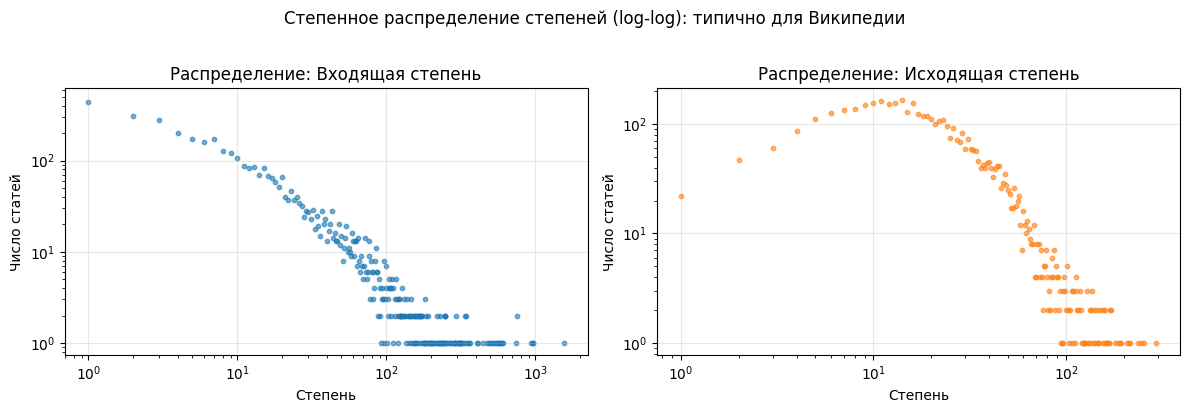


РАССТОЯНИЯ В ГРАФЕ (приближённо, выборка 200 стартов)
Среднее кратчайшее расстояние: 3.19
Медиана:                       3
Максимум (диаметр ≈):          8

Граф и признаки готовы к использованию в Ролях 1–3.
Доступные объекты: G, in_degree, out_degree, pagerank, idx, D


In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
from collections import Counter
from urllib.parse import unquote
import matplotlib.pyplot as plt

# ============================================================
# 1. ЗАГРУЗКА СВЯЗЕЙ И ПОСТРОЕНИЕ ГРАФА
# ============================================================
# links.tsv: два столбца (src, tgt), имена URL-encoded
links = pd.read_csv(f'{BASE}/links.tsv', sep='\t', header=None,
                    names=['src', 'tgt'], comment='#', quoting=3)
links['src'] = links['src'].apply(unquote)
links['tgt'] = links['tgt'].apply(unquote)

# Строим НАПРАВЛЕННЫЙ граф: ссылка ведёт от src к tgt
G = nx.from_pandas_edgelist(links, 'src', 'tgt', create_using=nx.DiGraph())

print("=" * 60)
print("СВОДКА О ГРАФЕ WIKISPEEDIA")
print("=" * 60)
print(f"Узлов (статей):        {G.number_of_nodes():>8,}")
print(f"Рёбер (ссылок):        {G.number_of_edges():>8,}")
print(f"Плотность графа:       {nx.density(G):.6f}")
print(f"Средняя исходящая степень: {G.number_of_edges() / G.number_of_nodes():.2f}")
print(f"Средняя входящая степень:  {G.number_of_edges() / G.number_of_nodes():.2f}")

# ============================================================
# 2. СТЕПЕНИ И ХАБЫ
# ============================================================
in_degree  = dict(G.in_degree())
out_degree = dict(G.out_degree())

# Топ-10 по входящей степени: это и есть «хабы» из West & Leskovec
print("\n" + "=" * 60)
print("ТОП-10 ХАБОВ ПО ВХОДЯЩЕЙ СТЕПЕНИ")
print("(именно на такие статьи люди сворачивают в начале пути)")
print("=" * 60)
top_in = sorted(in_degree.items(), key=lambda x: -x[1])[:10]
for name, deg in top_in:
    print(f"  {deg:>6,}  {name}")

print("\nТОП-10 ПО ИСХОДЯЩЕЙ СТЕПЕНИ (статьи с максимальным числом ссылок):")
top_out = sorted(out_degree.items(), key=lambda x: -x[1])[:10]
for name, deg in top_out:
    print(f"  {deg:>6,}  {name}")

# ============================================================
# 3. PAGE RANK
# ============================================================
# PageRank — это «вероятность случайно попасть на статью»;
# хорошая мера важности узла, тесно связанная со степенью.
print("\nСчитаем PageRank...")
pagerank = nx.pagerank(G, alpha=0.85)

print("\nТОП-10 ПО PAGERANK:")
for name, pr in sorted(pagerank.items(), key=lambda x: -x[1])[:10]:
    print(f"  {pr:.6f}  {name}")

# ============================================================
# 4. СВЯЗНОСТЬ И РАЗМЕРЫ КОМПОНЕНТ
# ============================================================
# Слабо связная компонента: если игнорировать направление рёбер,
# все ли узлы достижимы друг из друга?
components = list(nx.weakly_connected_components(G))
print("\n" + "=" * 60)
print("СВЯЗНОСТЬ ГРАФА")
print("=" * 60)
print(f"Число слабо связных компонент: {len(components)}")
print(f"Размер крупнейшей компоненты:  {max(len(c) for c in components):,} "
      f"({max(len(c) for c in components)/G.number_of_nodes()*100:.1f}% узлов)")

# Проверка: является ли граф сильно связным (достижим ли каждый из каждого)?
# Это дорогая операция, поэтому делаем только для проверки на подвыборке,
# а полную проверку опускаем (для 4600 узлов это может занять время).
# Вместо этого используем уже загруженную матрицу D (Floyd-Warshall):
# доля недостижимых пар = 12.3% (вы это уже видели).

# ============================================================
# 5. РАСПРЕДЕЛЕНИЕ СТЕПЕНЕЙ (лог-лог)
# ============================================================
# Степени в Википедии распределены по степенному закону:
# много статей с малой степенью, единицы — с огромной.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, deg_dict, title, color in [
    (axes[0], in_degree,  'Входящая степень',  'tab:blue'),
    (axes[1], out_degree, 'Исходящая степень', 'tab:orange'),
]:
    vals = list(deg_dict.values())
    # Строим гистограмму в лог-лог масштабе
    counts = Counter(vals)
    xs = sorted(counts)
    ys = [counts[x] for x in xs]
    ax.scatter(xs, ys, s=10, alpha=0.6, color=color)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Степень')
    ax.set_ylabel('Число статей')
    ax.set_title(f'Распределение: {title}')
    ax.grid(True, alpha=0.3)

plt.suptitle('Степенное распределение степеней (log-log): типично для Википедии', y=1.02)
plt.tight_layout()
plt.show()

# ============================================================
# 6. ДИАМЕТР И СРЕДНЕЕ КРАТЧАЙШЕЕ РАССТОЯНИЕ
# ============================================================
# Внимание: для графа из 4600 узлов это может занять 10-30 секунд.
# Используем приближение на выборке 200 узлов, чтобы не ждать долго.
import random
random.seed(42)
sample_nodes = random.sample(list(G.nodes), 600)
approx_distances = []

for src in sample_nodes:
    # BFS от каждого узла выборки до всех остальных
    dists = nx.single_source_shortest_path_length(G, src)
    approx_distances.extend(dists.values())

approx_distances = np.array(approx_distances)
print("\n" + "=" * 60)
print("РАССТОЯНИЯ В ГРАФЕ (приближённо, выборка 600 стартов)")
print("=" * 60)
print(f"Среднее кратчайшее расстояние: {approx_distances.mean():.2f}")
print(f"Медиана:                       {np.median(approx_distances):.0f}")
print(f"Максимум (диаметр ≈):          {approx_distances.max()}")

# ============================================================
# 7. СОХРАНЕНИЕ ПРИЗНАКОВ ДЛЯ ДРУГИХ РОЛЕЙ
# ============================================================
# Эти объекты будут использоваться в Ролях 1, 2 и 3.
# in_degree, out_degree, pagerank уже созданы выше.

# Маппинг «имя статьи -> индекс в матрице D»
# (нужен для быстрого доступа к расстояниям)
articles = pd.read_csv(f'{BASE}/articles.tsv', sep='\t', header=None,
                       names=['article'], comment='#', quoting=3)
articles['name'] = articles['article'].apply(unquote)
idx = {name: i for i, name in enumerate(articles['name'])}

print("\nГраф и признаки готовы к использованию в Ролях 1–3.")
print("Доступные объекты: G, in_degree, out_degree, pagerank, idx, D")